# Dissertation 分析 —— 游戏样本空间 TF-IDF 聚类版

相比早期「标签语义空间聚类」的核心改动：

| 早期做法 | 现在做法 |
|---------|---------|
| 对**标签名**做 TF-IDF(KMeans)，得到标签簇 | 对**游戏样本**做 TF-IDF(KMeans)，一个簇 = 一群游戏 |
| 每个「标签名」是一个文档 | 每个游戏是一篇文档，其标签集合作为「词」 |

每个簇的中心（TF-IDF 权重最高的标签）代表该题材的**定义性标签**，且天然与后面 Cohen's h 突显度分析统一。

## 0. 环境与配置

In [ ]:
# -*- coding: utf-8 -*-
import sys

# 让 stdout 使用 UTF-8，避免 Windows GBK 控制台编码中文/符号报错
if sys.version_info >= (3, 7):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
        sys.stderr.reconfigure(encoding="utf-8")
    except Exception:
        pass

import ast
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 12, "figure.dpi": 150})

# ==================== 研究参数配置（直接在此修改） ====================
DATA_PATH = "01_data/raw/steam_games_march2025_updated.csv"  # 数据文件（相对路径）
TAG_SOURCE_COL = "extracted_tags"                # 标签来源列

# ---- 数据清洗阈值 ----
YEAR_MIN, YEAR_MAX = 2015, 2025
MIN_REVIEWS = 100

# ---- 聚类参数 ----
N_CLUSTERS = 8                  # 游戏主题簇数量（依据 Grelier 等方法, K=8）
MIN_TAG_DOC_FREQ = 0.001        # 标签的最低文档频率（过滤极端稀疏标签，避免噪音）

# ---- 焦点簇（用于构造分类控制变量，可根据聚类结果人工挑选）----
FOCUS_CLUSTERS = [0, 1, 2, 3, 4, 5, 6, 7]  # K=8 下覆盖全部分簇（依据实际语义调整）

# ---- 输出 ----
OUTPUT_MEGATAG_CSV = "01_data/processed/cluster_megatag_reference.csv"
OUTPUT_DATA_CSV   = "01_data/processed/games_clustered_meta_export.csv"       # 富化后的"每款游戏"级数据
OUTPUT_COHEN_CSV  = "01_data/processed/cluster_cohens_h_tags.csv"             # 每簇 Cohen's h 定义标签
OUTPUT_FIGURE = "02_pipeline/figures/dissertation_figures.png"


## 1. 统一列表解析函数

In [ ]:
def parse_list_field(x):
    """统一解析「列表格式」字段：["a","b"] / "a, b" / 已解析的 list 等。"""
    if x is None:
        return []
    if isinstance(x, (float, np.floating)) and pd.isna(x):
        return []
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        if s[:1] in ("[", "(") and s[-1:] in ("]", ")"):
            try:
                val = ast.literal_eval(s)
                if isinstance(val, (list, tuple, set)):
                    return [str(t).strip() for t in val if str(t).strip()]
            except (ValueError, SyntaxError):
                pass
        return [t.strip() for t in s.split(",") if t.strip()]
    if isinstance(x, (list, tuple, set, np.ndarray)):
        return [str(t).strip() for t in x if str(t).strip()]
    val = str(x).strip()
    return [val] if val else []


## 2. 加载数据

In [ ]:
print("=" * 60)
print("Step 0: 加载数据")
print("=" * 60)

USECOLS = [
    "appid", "name", "release_date", "price", "dlc_count",
    "windows", "mac", "linux", "metacritic_score", "recommendations",
    "developers", "publishers", "positive", "negative", "estimated_owners",
    "average_playtime_forever", "median_playtime_forever", "extracted_tags", "genres", "categories",
    "tags", "tags_counts",
]
raw = pd.read_csv(DATA_PATH, usecols=USECOLS)
print(f"数据形状: {raw.shape}")


Step 0: 加载数据
数据形状: (89618, 22)


In [ ]:
def parse_tags_counts_with_priority(x, priority_threshold=0.3):
    """
    解析 tags_counts 并使用 Priority 过滤。
    假设 x 的格式类似于 "{'RPG': 1000, 'Action': 500, 'Funny': 10}"
    """
    if pd.isna(x):
        return []
    try:
        # 将字符串字典转换为真实字典
        tag_dict = ast.literal_eval(str(x))
        if not isinstance(tag_dict, dict) or len(tag_dict) == 0:
            return []
        
        # 找到该游戏得票最高的标签票数
        max_votes = max(tag_dict.values())
        if max_votes == 0:
            return []
        
        # 核心逻辑：计算 Priority Score，只保留大于阈值的核心标签
        valid_tags = []
        for tag, votes in tag_dict.items():
            priority = votes / max_votes
            if priority >= priority_threshold:
                valid_tags.append(str(tag).strip())
        return valid_tags
    except (ValueError, SyntaxError):
        return []

## 3. 数据预处理与过滤

In [ ]:
print("\n" + "=" * 60)

print("Step 1: 数据预处理与过滤")
print("=" * 60)

data = raw.copy()
data = data.dropna(subset=["genres", "categories", "tags_counts"])

data["release_date"] = pd.to_datetime(data["release_date"], errors="coerce")
data["Release_Year"] = data["release_date"].dt.year
data["Total_Reviews"] = data["positive"] + data["negative"]

original_len = len(data)

# 过滤：年份区间 + 商业门槛
data = data[(data["Release_Year"] >= YEAR_MIN) & (data["Release_Year"] <= YEAR_MAX)]
data = data[data["Total_Reviews"] >= MIN_REVIEWS]
data["Game_Age"] = 2025 - data["Release_Year"]

# 解析 genres，排除「非 Indie 但 owner 规模巨大」的样本
data["genres_list"] = data["genres"].apply(parse_list_field)
owners_to_exclude = [
    "5000000-10000000", "10000000-20000000", "20000000-50000000",
    "50000000-100000000", "100000000-200000000", "200000000-500000000",
]
owners_norm = data["estimated_owners"].astype(str).str.replace(r"\s+", "", regex=True)
non_indie_large = (~data["genres_list"].apply(lambda g: "Indie" in g)) & owners_norm.isin(owners_to_exclude)
data = data[~non_indie_large]

# 3. Tag Priority 降噪过滤
data["Clean_Priority_Tags"] = data["tags"].apply(lambda x: parse_tags_counts_with_priority(x, 0.3))
# [实] 该过滤实测删除 0 行：每款游戏票数最高的标签 priority 恒为 1.0 >= 0.3。
#      详见 06_tools/threshold_03_report.md（样本框逐级核对）。
data = data[data["Clean_Priority_Tags"].apply(len) > 0]

# 解析标签，去除无标签样本
#data["Clean_Meta_Tags"] = data[TAG_SOURCE_COL].apply(parse_list_field)
#data = data[data["Clean_Meta_Tags"].apply(len) > 0]
data["Clean_Meta_Tags"] = data["Clean_Priority_Tags"].apply(lambda tags: list(dict.fromkeys(tags)))

print(f"原始数据行数: {original_len}, 过滤后数据行数: {len(data)}")
print(data[["Clean_Meta_Tags"]].head())

all_tags = [t for sub in data["Clean_Meta_Tags"] for t in sub]
print(f"总唯一标签数: {len(set(all_tags))}")
print(f"样本标签示例: {sorted(set(all_tags))[:10]}")
print("保存总标签列表至TXT文件")
print("=" * 60)

with open("01_data/processed/all_tags.txt", "w", encoding="utf-8") as f:
    for tag in sorted(set(all_tags)):
        f.write(tag + "\n")

print(f"已生成 all_tags.txt，共包含 {len(set(all_tags))} 个标签")



Step 1: 数据预处理与过滤
原始数据行数: 88618, 过滤后数据行数: 17686
                                      Clean_Meta_Tags
7   [Survival, Crafting, Multiplayer, Open World, ...
13  [Farming Sim, Pixel Graphics, Multiplayer, Lif...
20  [Horror, Online Co-Op, Multiplayer, Psychologi...
25  [Free to Play, Survival, Zombies, Multiplayer,...
26  [Open World Survival Craft, Survival, Multipla...
总唯一标签数: 448
样本标签示例: ['1980s', "1990's", '2.5D', '2D', '2D Fighter', '2D Platformer', '360 Video', '3D', '3D Fighter', '3D Platformer']
保存总标签列表至TXT文件
已生成 all_tags.txt，共包含 448 个标签


## 4. 在【游戏样本】上做 Grelier priority + KMeans 聚类

> 每个游戏 = 一篇文档，其标签 = 词的集合。这是本题的核心改动。

In [ ]:
# ============================================================
# Step 2（方案甲）：基于 Meta_Tags priority 的 Grelier 聚类 —— 函数定义
# 实际执行在 Step 3（cell 中的 META_DICT 就绪处）调用。
# 用完整 tags 字典做全量合并（保留长尾），再以 priority 数值矩阵聚类。
# ============================================================

def _parse_tags_dict(x):
    """把 tags 列解析成 {标签: 票数} 字典；失败返回 {}。"""
    if x is None:
        return {}
    if isinstance(x, dict):
        return {str(k).strip(): v for k, v in x.items()}   # C2: 键空白归一化
    if isinstance(x, str):
        try:
            v = ast.literal_eval(x)
            return ({str(k).strip(): v for k, v in v.items()}
                    if isinstance(v, dict) else {})            # C2: 键空白归一化
        except Exception:
            return {}
    return {}


def build_meta_fields(data, META_DICT):
    """全量合并：产出 Meta_Tags(字符串列表) + Meta_Tags_Votes(元标签票数=组内max)
    + Meta_Tags_Priority(priority 归一化)。在完整 tags 字典上做，不先砍 0.3 阈值。"""
    votes, names = [], []
    for _, row in data.iterrows():
        tag_dict = _parse_tags_dict(row["tags"])
        meta_votes, meta_names = {}, set()
        for tag, v in tag_dict.items():
            mapped = META_DICT.get(tag, tag)
            if mapped == 'IGNORE':
                continue
            meta_names.add(mapped)
            meta_votes[mapped] = max(meta_votes.get(mapped, 0), v)
        votes.append(meta_votes)
        names.append(list(meta_names))
    data["Meta_Tags"] = names
    data["Meta_Tags_Votes"] = votes
    pri_list = []
    for v in votes:
        if not v:
            pri_list.append({})
            continue
        mx = max(v.values())
        pri_list.append({k: val / mx for k, val in v.items()})
    data["Meta_Tags_Priority"] = pri_list
    return data


def fit_priority_cluster(data, n_clusters=8):
    """Grelier priority 数值矩阵 + KMeans。不套白名单，保留题材细分颗粒度。
    产出 data["Game_Cluster"] 与 data["cluster_top_tags"]。"""
    all_meta = sorted(set(m for mp in data["Meta_Tags_Priority"] for m in mp))
    idx_of = {m: i for i, m in enumerate(all_meta)}
    mat = np.zeros((len(data), len(all_meta)))
    for i, mp in enumerate(data["Meta_Tags_Priority"]):
        for k, v in mp.items():
            mat[i, idx_of[k]] = v
    km = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
    data["Game_Cluster"] = km.fit_predict(mat)
    centroids = km.cluster_centers_
    global cluster_top_tags
    cluster_top_tags = {}
    for c in range(n_clusters):
        idx = np.argsort(centroids[c])[::-1][:10]
        cluster_top_tags[c] = [all_meta[i] for i in idx]
    return data


## 5. 构造研究变量（基于游戏簇）

In [ ]:
print("\n" + "=" * 60)
print("Step 3: 基于 VGMS 的元标签映射与变量中心化")
print("=" * 60)

# 定义降维字典 (Meta-Tag Dictionary, 依据 Windleharth 2016 框架构建)
# 你需要根据你打印出的 450个全量标签，把类似的词放在一个主类里
# =====================================================================
# VGMS Meta-Tag Dictionary (Optimized for Hybridization Index Validity)
# =====================================================================

META_DICT = {
    # ---------------- 1. 核心玩法与机制 (Mechanics & Genre) ----------------
    'JRPG': 'RPG', 'CRPG': 'RPG', 'Action RPG': 'RPG', 'Tactical RPG': 'RPG', 
    'Strategy RPG': 'RPG', 'Party-Based RPG': 'RPG', 'MMORPG': 'RPG', 
    'Dungeon Crawler': 'RPG', 'Mystery Dungeon': 'RPG', 'RPG': 'RPG',
    
    'FPS': 'Shooter', 'Third-Person Shooter': 'Shooter', 'Twin Stick Shooter': 'Shooter', 
    'Top-Down Shooter': 'Shooter', 'Arena Shooter': 'Shooter', 'Boomer Shooter': 'Shooter', 
    'Extraction Shooter': 'Shooter', 'Hero Shooter': 'Shooter', 'Looter Shooter': 'Shooter', 
    'On-Rails Shooter': 'Shooter', 'Shoot \'Em Up': 'Shooter', 'Sniper': 'Shooter', 
    'Bullet Hell': 'Shooter', 'Shooter': 'Shooter',
    
    'Farming Sim': 'Simulation', 'Life Sim': 'Simulation', 'Management': 'Simulation', 
    'City Builder': 'Simulation', 'Base Building': 'Simulation', 'Base-Building': 'Simulation', 
    'Colony Sim': 'Simulation', 'Automobile Sim': 'Simulation', 'Hobby Sim': 'Simulation', 
    'Job Simulator': 'Simulation', 'Medical Sim': 'Simulation', 'Outbreak Sim': 'Simulation', 
    'Political Sim': 'Simulation', 'Space Sim': 'Simulation', 'God Game': 'Simulation', 
    'Farming': 'Simulation', 'Simulation': 'Simulation',
    
    'Action Roguelike': 'Roguelike', 'Rogue-lite': 'Roguelike', 'Rogue-like': 'Roguelike', 
    'Roguelike Deckbuilder': 'Roguelike', 'Roguevania': 'Roguelike', 'Traditional Roguelike': 'Roguelike',
    
    'Turn-Based Tactics': 'Strategy', 'Turn-Based Strategy': 'Strategy', 'Grand Strategy': 'Strategy', 
    'RTS': 'Strategy', 'Real Time Tactics': 'Strategy', '4X': 'Strategy', 'Auto Battler': 'Strategy', 
    'Tower Defense': 'Strategy', 'MOBA': 'Strategy', 'Wargame': 'Strategy', 'Strategy': 'Strategy',
    
    '2D Fighter': 'Fighting/Brawler', '3D Fighter': 'Fighting/Brawler', 'Beat \'em up': 'Fighting/Brawler', 
    'Character Action Game': 'Fighting/Brawler', 'Hack and Slash': 'Fighting/Brawler', 
    'Spectacle fighter': 'Fighting/Brawler', 'Fighting': 'Fighting/Brawler', 'Martial Arts': 'Fighting/Brawler', 
    'Musou': 'Fighting/Brawler', 'Vehicular Combat': 'Fighting/Brawler', 'Swordplay': 'Fighting/Brawler',
    
    '2D Platformer': 'Platformer', '3D Platformer': 'Platformer', 'Precision Platformer': 'Platformer', 
    'Puzzle-Platformer': 'Platformer', 'Metroidvania': 'Platformer', 'Runner': 'Platformer', 
    'Platformer': 'Platformer', 'Parkour': 'Platformer',
    
    'Racing': 'Sports/Racing', 'Sports': 'Sports/Racing', 'Baseball': 'Sports/Racing', 
    'Basketball': 'Sports/Racing', 'Bowling': 'Sports/Racing', 'Boxing': 'Sports/Racing', 
    'Cricket': 'Sports/Racing', 'Cycling': 'Sports/Racing', 'Football (American)': 'Sports/Racing', 
    'Football (Soccer)': 'Sports/Racing', 'Golf': 'Sports/Racing', 'Hockey': 'Sports/Racing', 
    'Mini Golf': 'Sports/Racing', 'Rugby': 'Sports/Racing', 'Skateboarding': 'Sports/Racing', 
    'Skating': 'Sports/Racing', 'Skiing': 'Sports/Racing', 'Snowboarding': 'Sports/Racing', 
    'Snooker': 'Sports/Racing', 'Tennis': 'Sports/Racing', 'Volleyball': 'Sports/Racing', 
    'Wrestling': 'Sports/Racing', 'BMX': 'Sports/Racing', 'Motocross': 'Sports/Racing', 
    'Motorbike': 'Sports/Racing', 'Combat Racing': 'Sports/Racing', 'ATV': 'Sports/Racing', 
    'Driving': 'Sports/Racing', 'Offroad': 'Sports/Racing', 'Sailing': 'Sports/Racing',
    
    'Puzzle': 'Puzzle/Board', 'Board Game': 'Puzzle/Board', 'Card Game': 'Puzzle/Board', 
    'Card Battler': 'Puzzle/Board', 'Deckbuilding': 'Puzzle/Board', 'Trading Card Game': 'Puzzle/Board', 
    'Chess': 'Puzzle/Board', 'Dice': 'Puzzle/Board', 'Logic': 'Puzzle/Board', 'Match 3': 'Puzzle/Board', 
    'Sokoban': 'Puzzle/Board', 'Solitaire': 'Puzzle/Board', 'Tabletop': 'Puzzle/Board', 
    'Tile-Matching': 'Puzzle/Board', 'Trivia': 'Puzzle/Board', 'Word Game': 'Puzzle/Board', 
    'Hidden Object': 'Puzzle/Board', 'Mahjong': 'Puzzle/Board', 'Spelling': 'Puzzle/Board', 
    'Pinball': 'Puzzle/Board',
    
    'Point & Click': 'Adventure/Narrative', 'Visual Novel': 'Adventure/Narrative', 
    'Walking Simulator': 'Adventure/Narrative', 'Dating Sim': 'Adventure/Narrative', 
    'Otome': 'Adventure/Narrative', 'Escape Room': 'Adventure/Narrative', 'Text-Based': 'Adventure/Narrative', 
    'Choose Your Own Adventure': 'Adventure/Narrative', 'Interactive Fiction': 'Adventure/Narrative',
    
    'Crafting': 'Core System', 'Survival': 'Core System', 'Open World': 'Core System', 
    'Open World Survival Craft': 'Core System', 'Sandbox': 'Core System', 'Procedural Generation': 'Core System', 
    'Loot': 'Core System', 'Perma Death': 'Core System', 'Inventory Management': 'Core System', 
    'Stealth': 'Core System', 'Souls-like': 'Core System', 'Boss Rush': 'Core System', 
    'Automation': 'Core System', 'Resource Management': 'Core System',

    # ---------------- 2. 主题与设定 (Theme & Setting) ----------------
    'Sci-fi': 'Sci-Fi/Cyberpunk', 'Cyberpunk': 'Sci-Fi/Cyberpunk', 'Futuristic': 'Sci-Fi/Cyberpunk', 
    'Space': 'Sci-Fi/Cyberpunk', 'Aliens': 'Sci-Fi/Cyberpunk', 'Mechs': 'Sci-Fi/Cyberpunk', 
    'Robots': 'Sci-Fi/Cyberpunk', 'Transhumanism': 'Sci-Fi/Cyberpunk', 'Dystopian': 'Sci-Fi/Cyberpunk', 
    'Steampunk': 'Sci-Fi/Cyberpunk',
    
    'Fantasy': 'Fantasy/Magic', 'Magic': 'Fantasy/Magic', 'Dragons': 'Fantasy/Magic', 
    'Demons': 'Fantasy/Magic', 'Vampire': 'Fantasy/Magic', 'Mythology': 'Fantasy/Magic', 
    'Supernatural': 'Fantasy/Magic',
    
    'Historical': 'Historical', 'Medieval': 'Historical', 'Rome': 'Historical', 
    'Vikings': 'Historical', 'World War I': 'Historical', 'World War II': 'Historical', 
    'Cold War': 'Historical', 'Western': 'Historical', 'Alternate History': 'Historical',
    
    'Military': 'Military/Combat', 'War': 'Military/Combat', 'Tanks': 'Military/Combat', 
    'Naval': 'Military/Combat', 'Naval Combat': 'Military/Combat', 'Assassin': 'Military/Combat', 
    'Ninja': 'Military/Combat', 'Pirates': 'Military/Combat',
    
    'Crime': 'Other Themes', 'Heist': 'Other Themes', 'Lovecraftian': 'Other Themes', 
    'Post-apocalyptic': 'Other Themes', 'Zombies': 'Other Themes', 'Gothic': 'Other Themes',

    # ---------------- 3. 叙事与情感维度 (Aesthetics in MDA) ----------------
    'Story Rich': 'Story-Driven', 'Lore-Rich': 'Story-Driven', 'Drama': 'Story-Driven', 
    'Epic': 'Story-Driven', 'Detective': 'Story-Driven', 'Mystery': 'Story-Driven',
    
    'Relaxing': 'Mood (Positive)', 'Cozy': 'Mood (Positive)', 'Wholesome': 'Mood (Positive)', 
    'Funny': 'Mood (Positive)', 'Comedy': 'Mood (Positive)', 'Cute': 'Mood (Positive)',
    
    'Dark': 'Mood (Dark)', 'Horror': 'Mood (Dark)', 'Psychological Horror': 'Mood (Dark)', 
    'Survival Horror': 'Mood (Dark)', 'Thriller': 'Mood (Dark)', 'Dark Fantasy': 'Mood (Dark)',

    # ---------------- 4. 视觉与视角 (Visual & Perspective) ----------------
    '2D': 'Perspective', '2.5D': 'Perspective', '3D': 'Perspective', 'First-Person': 'Perspective', 
    'Third Person': 'Perspective', 'Top-Down': 'Perspective', 'Isometric': 'Perspective',
    
    'Pixel Graphics': 'Art Style', 'Voxel': 'Art Style', 'Hand-drawn': 'Art Style', 
    'Minimalist': 'Art Style', 'Anime': 'Art Style', 'Retro': 'Art Style', 'Realistic': 'Art Style',

    # =====================================================================
    # 🚨 强制剔除的万金油标签与非设计标签 (MAPPED TO 'IGNORE')
    # =====================================================================
    # 泛滥/无意义的玩法标签
    'Action': 'Action', 'Adventure': 'Adventure/Narrative', 'Action-Adventure': 'Action',
    
    # 游玩人数/交互方式
    'Singleplayer': 'IGNORE', 'Multiplayer': 'IGNORE', 'Massively Multiplayer': 'IGNORE', 
    'Co-op': 'IGNORE', 'Online Co-Op': 'IGNORE', 'Local Co-Op': 'IGNORE', 'PvP': 'IGNORE', 'PvE': 'IGNORE',
    'Controller': 'IGNORE', 'Mouse only': 'IGNORE', 'VR': 'IGNORE', "360 Video": 'IGNORE', "3D Vision": 'IGNORE', 
    "4 Player Local": 'IGNORE', "8-bit Music": 'IGNORE', "Asymmetric VR": 'IGNORE', "Asynchronous Multiplayer": 'IGNORE',
    "Local Multiplayer": 'IGNORE', 

    
    # 商业模式/受众/外部评价
    'Indie': 'IGNORE', 'Early Access': 'IGNORE', 'Free to Play': 'IGNORE', 'Crowdfunded': 'IGNORE',
    'Casual': 'Casual', 'Family Friendly': 'IGNORE', 'Mature': 'IGNORE', 'Gore': 'IGNORE', 
    'Masterpiece': 'IGNORE', 'Classic': 'IGNORE', 'Great Soundtrack': 'IGNORE', 'e-sports': 'IGNORE', 
    "Addictive": 'IGNORE', "Beautiful": 'IGNORE', "Benchmark": 'IGNORE', "Blood": 'IGNORE', "Memes": 'IGNORE', 
    "Mod": 'IGNORE', "Moddable": 'IGNORE', "Music": 'IGNORE',  "Replay Value": 'IGNORE', 
    
    # 软件与非游戏媒介
    'Software': 'IGNORE', 'Utilities': 'IGNORE', 'Game Development': 'IGNORE', 
    'Movie': 'IGNORE', 'Documentary': 'IGNORE', 'Soundtrack': 'IGNORE',

        # ===== 伴生诊断补丁（修正被预分组切开的标签）=====
    # Building 原本未覆盖，被保留成独立标签而 Sandbox 归 Core System -> 伴生被切开
    'Building': 'Simulation',
    # Sandbox 常与 Building/Base-Building 伴生，归入 Simulation 保持一致
    'Sandbox': 'Simulation',
    # 这几个原本未覆盖，补上归类
    'Agriculture': 'Simulation',
    'Economy': 'Simulation',
    'Transportation': 'Simulation', 

        # ===== 伴生合并 · A类（语义重复，避免虚增杂交度）=====
    'Party': 'Party',              # 建一个 Party 类（或并入 Casual/Cozy）
    'Party Game': 'Party',
    'Choices Matter': 'Adventure/Narrative',
    'Multiple Endings': 'Adventure/Narrative',
    # ===== 伴生保留 R类 · 仅为未覆盖标签补登记（不改变伴生结构）=====
    'Romance': 'Adventure/Narrative', 'LGBTQ+': 'Adventure/Narrative', 'Dating': 'Adventure/Narrative',
    'Investigation': 'Story-Driven', 
    #===== 成人内容单独标记补充 ======
    'Adult': 'Adult', 'Hentai': 'Adult', 'NSFW': 'Adult',
    'Nudity': 'Adult', 'Sexual Content': 'Adult',
    'Eroge': 'Adult', 'Visual Novel (Adult)': 'Adult', 'Hentai(Nudity)': 'Adult',
        # ===== 按 Li(2020) EFA 分组的完整修正补丁 =====
    "Resource Management": "Simulation",
    "Time Management": "Simulation",
    "Twin Stick Shooter": "Arcade/Top-Down Shooter",
    "Top-Down Shooter": "Arcade/Top-Down Shooter",
    "Shoot 'Em Up": "Arcade/Top-Down Shooter",
    "Bullet Hell": "Arcade/Top-Down Shooter"

}

# --- C2 修正：字典键空白归一化 -------------------------------------
# 原始数据里存在 'Dystopian ' / 'Parody ' 这类带尾随空格的标签；
# 对字典键与查询键同时 strip() 才能正确归并（实测影响 -0.010 个维度）。
META_DICT = {str(k).strip(): v for k, v in META_DICT.items()}


# ============================================================
# 方案甲执行（改动1+2+3）：全量合并 + priority 数值矩阵聚类（Grelier 一致）
# 全量合并（保留完整 tags 的长尾），元标签票数=组内 max，聚类改用 KMeans on priority
# ============================================================
data = build_meta_fields(data, META_DICT)
data = fit_priority_cluster(data, N_CLUSTERS)
print("聚类：Game_Cluster 已由 Meta_Tags priority 矩阵生成")
print("各簇规模:")
for c in range(N_CLUSTERS):
    _sz = int((data['Game_Cluster'] == c).sum())
    _tg = cluster_top_tags[c][:6]
    print(f"  Cluster {c}: {_sz} 款游戏 | 代表meta: {_tg}")

def map_to_metatags(tag_list):
    meta_tags = set()
    for tag in tag_list:
        mapped = META_DICT.get(tag, tag) # 如果字典里没有，就保留原样
        if mapped != 'IGNORE':
            meta_tags.add(mapped)
    return list(meta_tags)

# 映射并计算真实的杂交度
# 注意：Meta_Tags 已在上方 build_meta_fields 全量合并生成（改动2：保留长尾），不再从 Clean_Priority_Tags 重建
data["Hybridization_Index"] = data["Meta_Tags"].apply(len)

# 因变量
data["Log_Reviews"] = np.log1p(data["Total_Reviews"])

# --- 极其关键：中心化 (Mean-Centering) 解决多重共线性 VIF ---
hybrid_mean = data["Hybridization_Index"].mean()
data["Hybrid_Centered"] = data["Hybridization_Index"] - hybrid_mean
data["Hybrid_Centered_Squared"] = data["Hybrid_Centered"] ** 2

# 焦点簇处理 (照旧)
data["in_focus_cluster"] = data["Game_Cluster"].isin(FOCUS_CLUSTERS).astype(int)

# 打印分布，检查是否还有 20 封顶的问题！
print("真实的 Meta-Tag 杂交度分布:")
print(data[["Hybridization_Index", "Hybrid_Centered"]].describe().round(2))

# --- 再次进行 VIF 诊断 ---
# 注意：主模型按论文 Table 5.1 使用 Price-only（不含 Game_Age）
vif_cols = ["Hybrid_Centered", "Hybrid_Centered_Squared", "price"]
# 清理可能存在的缺失价(如果有)
vif_test_data = data[vif_cols].dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = vif_cols
vif_data["VIF"] = [
    variance_inflation_factor(vif_test_data.values, i) for i in range(len(vif_cols))
]
print("\n解决后核心变量 VIF 诊断 (目标: < 5):\n", vif_data)



Step 3: 基于 VGMS 的元标签映射与变量中心化
聚类：Game_Cluster 已由 Meta_Tags priority 矩阵生成
各簇规模:
  Cluster 0: 2181 款游戏 | 代表meta: ['Casual', 'Adventure/Narrative', 'Action', 'Puzzle/Board', 'Simulation', 'Strategy']
  Cluster 1: 2163 款游戏 | 代表meta: ['Adventure/Narrative', 'Story-Driven', 'Perspective', 'Mood (Dark)', 'Art Style', 'Atmospheric']
  Cluster 2: 1741 款游戏 | 代表meta: ['Mood (Positive)', 'Casual', 'Simulation', 'Perspective', 'Art Style', 'Adventure/Narrative']
  Cluster 3: 1341 款游戏 | 代表meta: ['RPG', 'Strategy', 'Perspective', 'Adventure/Narrative', 'Art Style', 'Fantasy/Magic']
  Cluster 4: 2478 款游戏 | 代表meta: ['Simulation', 'Strategy', 'Perspective', 'Core System', 'Sports/Racing', 'Art Style']
  Cluster 5: 2620 款游戏 | 代表meta: ['Adventure/Narrative', 'RPG', 'Art Style', 'Adult', 'Action', 'Story-Driven']
  Cluster 6: 1977 款游戏 | 代表meta: ['Action', 'Core System', 'Perspective', 'Adventure/Narrative', 'RPG', 'Art Style']
  Cluster 7: 3185 款游戏 | 代表meta: ['Action', 'Perspective', 'Art Style', 'Shooter'


Step 5: 主 OLS 回归 — 年份固定效应模型 (2015基准年)
                            OLS Regression Results                            
Dep. Variable:            Log_Reviews   R-squared:                       0.162
Model:                            OLS   Adj. R-squared:                  0.162
Method:                 Least Squares   F-statistic:                     262.9
Date:                Thu, 03 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:17:38   Log-Likelihood:                -31015.
No. Observations:               17670   AIC:                         6.206e+04
Df Residuals:                   17656   BIC:                         6.217e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

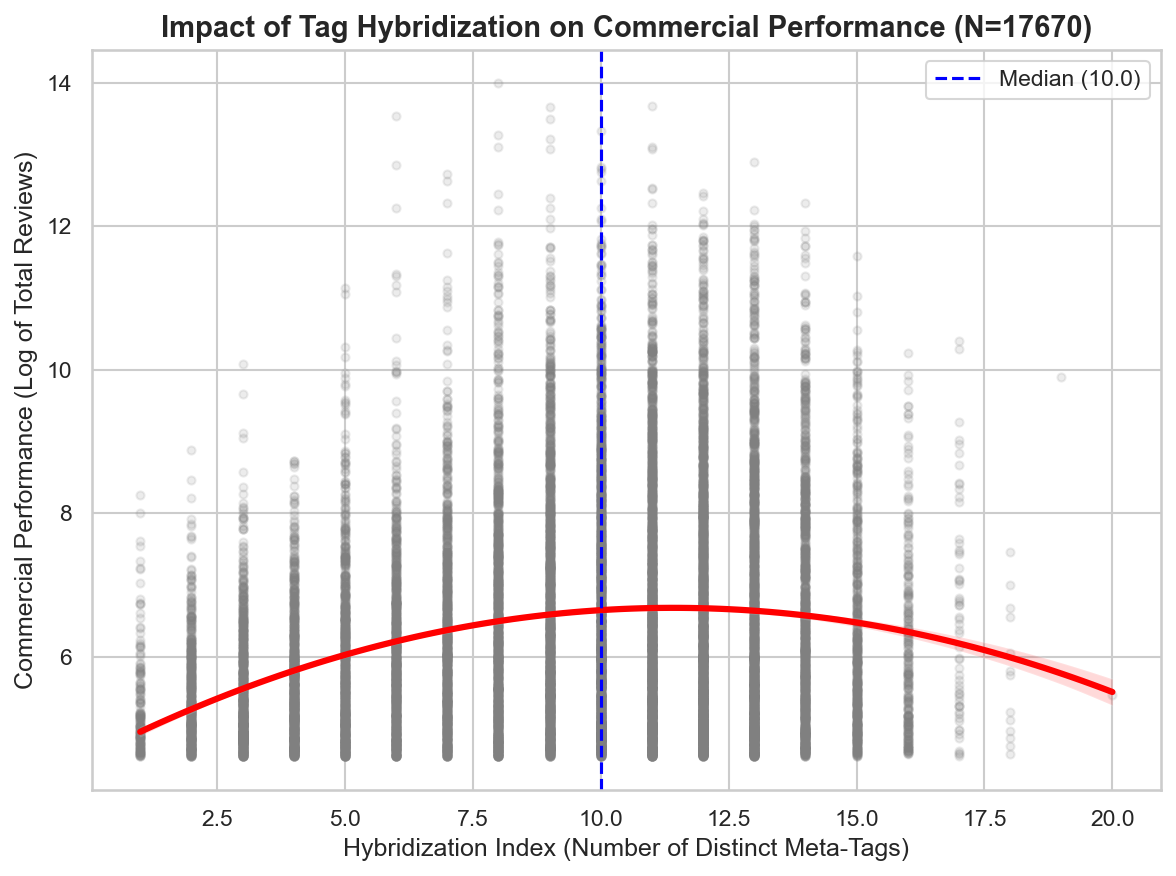

In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("\n" + "=" * 60)
print("Step 5: 主 OLS 回归 — 年份固定效应模型 (2015基准年)")
print("=" * 60)

# 1. 准备回归数据 (剔除空值，过滤杂交度为0的纯基准样本，保留 > 0 的有效混合样本)
reg_data = data[data["Hybridization_Index"] > 0].dropna(subset=[
    "Log_Reviews", "Hybrid_Centered", "Hybrid_Centered_Squared", "price"
])

Y = reg_data["Log_Reviews"]

# 2. 年份固定效应 (以 2015 为基准年，drop_first)
year_dum = pd.get_dummies(reg_data["Release_Year"], prefix="Y", drop_first=True, dtype=float).astype(float)

# 3. 主模型：Hc + Hc^2 + price + 年份FE
X_main = reg_data[["Hybrid_Centered", "Hybrid_Centered_Squared", "price"]].join(year_dum)
X_main = sm.add_constant(X_main)
final_model = sm.OLS(Y, X_main).fit(cov_type="HC3")   # C1: 论文全程使用 HC3
print(final_model.summary())

# 核心结果提取
lin = final_model.params["Hybrid_Centered"]
quad = final_model.params["Hybrid_Centered_Squared"]
hybrid_mean = data["Hybridization_Index"].mean()
peak = hybrid_mean + (-lin / (2 * quad))
print("\n=== 主模型核心结果 (年份固定效应) ===")
print(f"  N             = {int(final_model.nobs)}")
print(f"  R²            = {final_model.rsquared:.4f}")
print(f"  线性 β1 (Hc)  = {lin:+.5f}  (p={final_model.pvalues['Hybrid_Centered']:.4f})")
print(f"  二次 β2 (Hc²) = {quad:+.5f}  (p={final_model.pvalues['Hybrid_Centered_Squared']:.4f})")
print(f"  价格 β3       = {final_model.params['price']:+.5f}  (p={final_model.pvalues['price']:.4f})")
print(f"  指数均值       = {hybrid_mean:.2f}")
print(f"  最优点(peak)  = {peak:.2f}")

# ==========================================
# 绘制最终的 杂交度 vs 商业表现 曲线图
# ==========================================
plt.figure(figsize=(8, 6))

# 使用原始的 Hybridization_Index 画图，直观易懂
sns.regplot(
    data=reg_data,
    x='Hybridization_Index',
    y='Log_Reviews',
    order=2,  # 2阶多项式（允许拟合抛物线）
    scatter_kws={'alpha':0.15, 'color': 'gray', 's': 15},
    line_kws={'color': 'red', 'linewidth': 3}
)

plt.title('Impact of Tag Hybridization on Commercial Performance (N={})'.format(len(reg_data)), fontsize=14, fontweight='bold')
plt.xlabel('Hybridization Index (Number of Distinct Meta-Tags)', fontsize=12)
plt.ylabel('Commercial Performance (Log of Total Reviews)', fontsize=12)

# 添加基准线
plt.axvline(x=reg_data['Hybridization_Index'].median(), color='blue', linestyle='--', label=f"Median ({reg_data['Hybridization_Index'].median()})")
plt.legend()
plt.tight_layout()
plt.savefig("02_pipeline/figures/hybridization_curve.png", dpi=300)
plt.show()


## 稳健性检验（独立单元格）

以下各单元格独立运行，均复用上方 `data` 对象，检验倒U型结论在
不同时间控制设定与价格调制下的稳健性。

In [ ]:
print("\n" + "=" * 60)
print("稳健1 | Model 0: 无时间控制 (Price-only 基线)")
print("=" * 60)
X0 = sm.add_constant(reg_data[["Hybrid_Centered", "Hybrid_Centered_Squared", "price"]])
m0 = sm.OLS(Y, X0).fit(cov_type="HC3")   # C1
lin0 = m0.params["Hybrid_Centered"]; quad0 = m0.params["Hybrid_Centered_Squared"]
peak0 = hybrid_mean + (-lin0 / (2 * quad0))
print(f"  N = {int(m0.nobs)}  R² = {m0.rsquared:.4f}")
print(f"  Hc = {lin0:+.5f} (p={m0.pvalues['Hybrid_Centered']:.4f})")
print(f"  Hc² = {quad0:+.5f} (p={m0.pvalues['Hybrid_Centered_Squared']:.4f})")
print(f"  最优点 = {peak0:.2f}")


稳健1 | Model 0: 无时间控制 (Price-only 基线)
  N = 17670  R² = 0.1365
  Hc = +0.05224 (p=0.0000)
  Hc² = -0.01301 (p=0.0000)
  最优点 = 11.33


In [ ]:
print("\n" + "=" * 60)
print("稳健2 | 按天游戏年龄连续控制 (精确到日的暴露时长)")
print("=" * 60)
# 计算按天游戏年龄（数据抓取时点 2025-03-10）
cutoff = pd.Timestamp("2025-03-10")
reg_data["age_days"] = (cutoff - reg_data["release_date"]).dt.days
reg_data["age_days_c"] = reg_data["age_days"] - reg_data["age_days"].mean()

X_age = sm.add_constant(reg_data[["Hybrid_Centered", "Hybrid_Centered_Squared", "price", "age_days_c"]])
m_age = sm.OLS(Y, X_age).fit(cov_type="HC3")   # C1
linA = m_age.params["Hybrid_Centered"]; quadA = m_age.params["Hybrid_Centered_Squared"]
peakA = hybrid_mean + (-linA / (2 * quadA))
print(f"  N = {int(m_age.nobs)}  R² = {m_age.rsquared:.4f}")
print(f"  Hc = {linA:+.5f} (p={m_age.pvalues['Hybrid_Centered']:.4f})")
print(f"  Hc² = {quadA:+.5f} (p={m_age.pvalues['Hybrid_Centered_Squared']:.4f})")
print(f"  age_days = {m_age.params['age_days_c']:+.6f}")
print(f"  最优点 = {peakA:.2f}")


稳健2 | 按天游戏年龄连续控制 (精确到日的暴露时长)
  N = 17670  R² = 0.1604
  Hc = +0.07583 (p=0.0000)
  Hc² = -0.01462 (p=0.0000)
  age_days = +0.000243
  最优点 = 11.92


In [ ]:
print("\n" + "=" * 60)
print("稳健3 | 方案A: 价格调制 (年份FE + 杂交×价格交互)")
print("=" * 60)
reg2 = reg_data.copy()
pm = reg2["price"].mean()
reg2["price_c"] = reg2["price"] - pm
reg2["Hc_x_Price"] = reg2["Hybrid_Centered"] * reg2["price_c"]
reg2["Hc2_x_Price"] = reg2["Hybrid_Centered_Squared"] * reg2["price_c"]

X_inter = sm.add_constant(reg2[["Hybrid_Centered", "Hybrid_Centered_Squared", "price",
                                "Hc_x_Price", "Hc2_x_Price"]].join(year_dum))
m_inter = sm.OLS(Y, X_inter).fit(cov_type="HC3")   # C1
linI = m_inter.params["Hybrid_Centered"]; quadI = m_inter.params["Hybrid_Centered_Squared"]
peakI = hybrid_mean + (-linI / (2 * quadI))
print(f"  N = {int(m_inter.nobs)}  R² = {m_inter.rsquared:.4f}")
print(f"  Hc = {linI:+.5f} (p={m_inter.pvalues['Hybrid_Centered']:.4f})")
print(f"  Hc² = {quadI:+.5f} (p={m_inter.pvalues['Hybrid_Centered_Squared']:.4f})")
print(f"  Hc×Price = {m_inter.params['Hc_x_Price']:+.5f} (p={m_inter.pvalues['Hc_x_Price']:.4f})")
print(f"  Hc²×Price = {m_inter.params['Hc2_x_Price']:+.5f} (p={m_inter.pvalues['Hc2_x_Price']:.4f})")
print(f"  最优点 = {peakI:.2f}")


稳健3 | 方案A: 价格调制 (年份FE + 杂交×价格交互)
  N = 17670  R² = 0.1716
  Hc = +0.08373 (p=0.0000)
  Hc² = -0.01692 (p=0.0000)
  Hc×Price = +0.00326 (p=0.0000)
  Hc²×Price = -0.00032 (p=0.0000)
  最优点 = 11.80


In [ ]:
print("\n" + "=" * 60)
print("稳健4 | Tag-Priority 阈值序列 (固定样本, 只变索引定义)")
print("=" * 60)

def to_metatags(tag_list):
    """Map raw tags through the Meta-Tag dictionary, dropping IGNORE."""
    out = set()
    for tag in tag_list:
        key = str(tag).strip()
        mapped = META_DICT.get(key, key)
        if mapped != 'IGNORE':
            out.add(mapped)
    return list(out)

# --- C3 修正 -------------------------------------------------------------
# 原先该单元让样本随阈值 t 一起缩小（N 由 17,639 递减到 17,488）。实测（
# 06_tools/threshold_03_report.md）表明：priority >= t 的标签列表在全部七档
# 都是空的 0 行 —— 票数最高的标签 priority 恒为 1.0，阈值从不删行。N 的下降
# 全部来自 'IGNORE' 归并（阈值越高，幸存标签越少，越容易被 IGNORE 清空）。
# 因此那样会把「索引定义变化」与「样本构成变化」两个效应混在一起。
# 修正：样本固定为主模型回归样本 reg_data，每一档只重新定义杂交度。
# ------------------------------------------------------------------------
print(f"{'t':>6} {'N':>7} {'IndexMean':>10} {'H=0':>5} "
      f"{'beta1':>9} {'t':>7} {'beta2':>9} {'t':>7} {'Peak':>7} {'R2':>8}")
for t in [None, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]:
    if t is None:
        data['_Cpt'] = data['tags'].apply(lambda x: list(_parse_tags_dict(x).keys()))
    else:
        data['_Cpt'] = data['tags'].apply(lambda x: parse_tags_counts_with_priority(x, t))
    data['_Mt'] = data['_Cpt'].apply(to_metatags)
    hm = data['_Mt'].apply(len).mean()

    sub = reg_data.copy()
    sub['Hc_t'] = data.loc[sub.index, '_Mt'].apply(len) - hm
    sub['Hc_t2'] = sub['Hc_t'] ** 2
    X = sm.add_constant(sub[['Hc_t', 'Hc_t2', 'price']].join(year_dum))
    m = sm.OLS(sub['Log_Reviews'], X).fit(cov_type="HC3")   # C1
    pk = hm + (-m.params['Hc_t'] / (2 * m.params['Hc_t2']))
    tag = ' none' if t is None else f"{t:.2f}"
    print(f"{tag:>6} {int(m.nobs):>7} {hm:>10.4f} {int((data['_Mt'].apply(len) == 0).sum()):>5} "
          f"{m.params['Hc_t']:>+9.4f} {m.tvalues['Hc_t']:>+7.2f} "
          f"{m.params['Hc_t2']:>+9.4f} {m.tvalues['Hc_t2']:>+7.2f} {pk:>7.2f} {m.rsquared:>8.4f}")



稳健4 | Tag-Priority 阈值序列 (七挡, 年份固定效应版本)
     t       N  IndexMean     beta1     beta2    Peak       R2
0.15   17639       8.92   +0.0528   -0.0131   10.93   0.1384
0.20   17630       8.67   +0.0436   -0.0123   10.44   0.1305
0.25   17604       8.39   +0.0379   -0.0119    9.99   0.1258
0.30   17578       8.06   +0.0354   -0.0111    9.66   0.1217
0.35   17548       7.70   +0.0346   -0.0106    9.33   0.1190
0.40   17515       7.33   +0.0324   -0.0099    8.97   0.1158
0.45   17488       6.96   +0.0281   -0.0090    8.52   0.1135


## 6. 生成 Cluster → Megatag 对照参考表（附录用途）

In [ ]:
# ============================================================
# Step 6a（原预留空位）: 把管线产出的数据导出为新的 CSV 文件
# ============================================================

def _csv_s(x):
    """把 list/dict/数组列转成;分隔短串，便于干净写入 CSV。"""
    if x is None:
        return ""
    if isinstance(x, (list, tuple, set, np.ndarray)):
        return "; ".join(str(v) for v in x if str(v).strip())
    return str(x)


print("\n" + "=" * 60)
print("Step 6a: 导出管线生成的 CSV 产物")
print("=" * 60)

# ---------------- (A) 富化后的"每款游戏"级数据 ----------------
_m_cols = [
    "appid", "name", "Release_Year",
    "Clean_Priority_Tags", "Meta_Tags",
    "Game_Cluster", "in_focus_cluster",
    "Total_Reviews", "positive", "negative",
    "price",
    "Hybridization_Index", "Log_Reviews",
    "Hybrid_Centered", "Hybrid_Centered_Squared",
]
_m_cols = [c for c in _m_cols if c in data.columns]
export_df = data[_m_cols].copy()
for _c in ["Clean_Priority_Tags", "Meta_Tags"]:
    if _c in export_df.columns:
        export_df[_c] = export_df[_c].apply(_csv_s)
export_df.reset_index(drop=True).to_csv(OUTPUT_DATA_CSV, index=False, encoding="utf-8-sig")
print(f"已导出: {OUTPUT_DATA_CSV}  ({len(export_df)} 行 x {export_df.shape[1]} 列)")

# --------- (B) Cluster -> 定义性 Megatag 对照参考表（附录）---------
_rows = []
for _cid in range(N_CLUSTERS):
    _mem = data[data["Game_Cluster"] == _cid]
    _def = cluster_top_tags.get(_cid, [])[:5]
    _H = _mem["Meta_Tags"].apply(len)
    _rows.append({
        "cluster_id": _cid,
        "n_games": int(len(_mem)),
        "share_pct": round(100 * len(_mem) / len(data), 2),
        "defining_meta_tags": "; ".join(_def),
        "mean_hybrid_index": round(float(_H.mean()), 3),
        "median_hybrid_index": round(float(_H.median()), 3),
        "min_hybrid_index": int(_H.min()),
        "max_hybrid_index": int(_H.max()),
    })
cluster_ref = pd.DataFrame(_rows)
cluster_ref.to_csv(OUTPUT_MEGATAG_CSV, index=False, encoding="utf-8-sig")
print("\n已导出: " + OUTPUT_MEGATAG_CSV)
print(cluster_ref.to_string(index=False))

In [ ]:
print("\n" + "=" * 60)
print("Step 6: Cohen's h 突显度分析")
print("=" * 60)


def calculate_cohens_h(p1, p2):
    p1 = np.clip(p1, 0, 1)
    p2 = np.clip(p2, 0, 1)
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))


mlb = MultiLabelBinarizer()
tags_matrix = mlb.fit_transform(data["Meta_Tags"])
tags_df = pd.DataFrame(tags_matrix, columns=mlb.classes_, index=data.index)

min_freq = int(len(data) * 0.005)
valid_tags = tags_df.columns[tags_df.sum() >= min_freq]
tags_filtered = tags_df[valid_tags]

all_top_h = {}
for cid in range(N_CLUSTERS):
    member = data.index[data["Game_Cluster"] == cid]
    h_scores = {}
    for tag in valid_tags:
        p1 = tags_filtered.loc[member, tag].mean()  # 簇内比例
        p2 = tags_filtered[tag].mean()              # 全局比例
        h_scores[tag] = calculate_cohens_h(p1, p2)
    top_tags = sorted(h_scores.items(), key=lambda kv: kv[1], reverse=True)[:5]
    all_top_h[cid] = top_tags
    print(f"游戏簇 {cid} 的定义标签 (Cohen's h): "
          + ", ".join(f"{t}({h:.2f})" for t, h in top_tags))

# ---- 导出各簇 Cohen's h 突显度 Top 标签明细表 ----
_h_rows = []
for _cid in range(N_CLUSTERS):
    _member_idx = data.index[data["Game_Cluster"] == _cid]
    for _tag, _h in all_top_h[_cid]:
        _h_rows.append({
            "cluster_id": _cid,
            "meta_tag": _tag,
            "cohens_h": round(float(_h), 4),
            "share_in_cluster": round(float(tags_filtered.loc[_member_idx, _tag].mean()), 4),
            "share_global": round(float(tags_filtered[_tag].mean()), 4),
        })
cohen_export = pd.DataFrame(_h_rows)
cohen_export.to_csv(OUTPUT_COHEN_CSV, index=False, encoding="utf-8-sig")
print(f"\n已导出: {OUTPUT_COHEN_CSV}  ({len(cohen_export)} 条簇-标签记录)")

## 9. 学术可视化


Step 7: 可视化


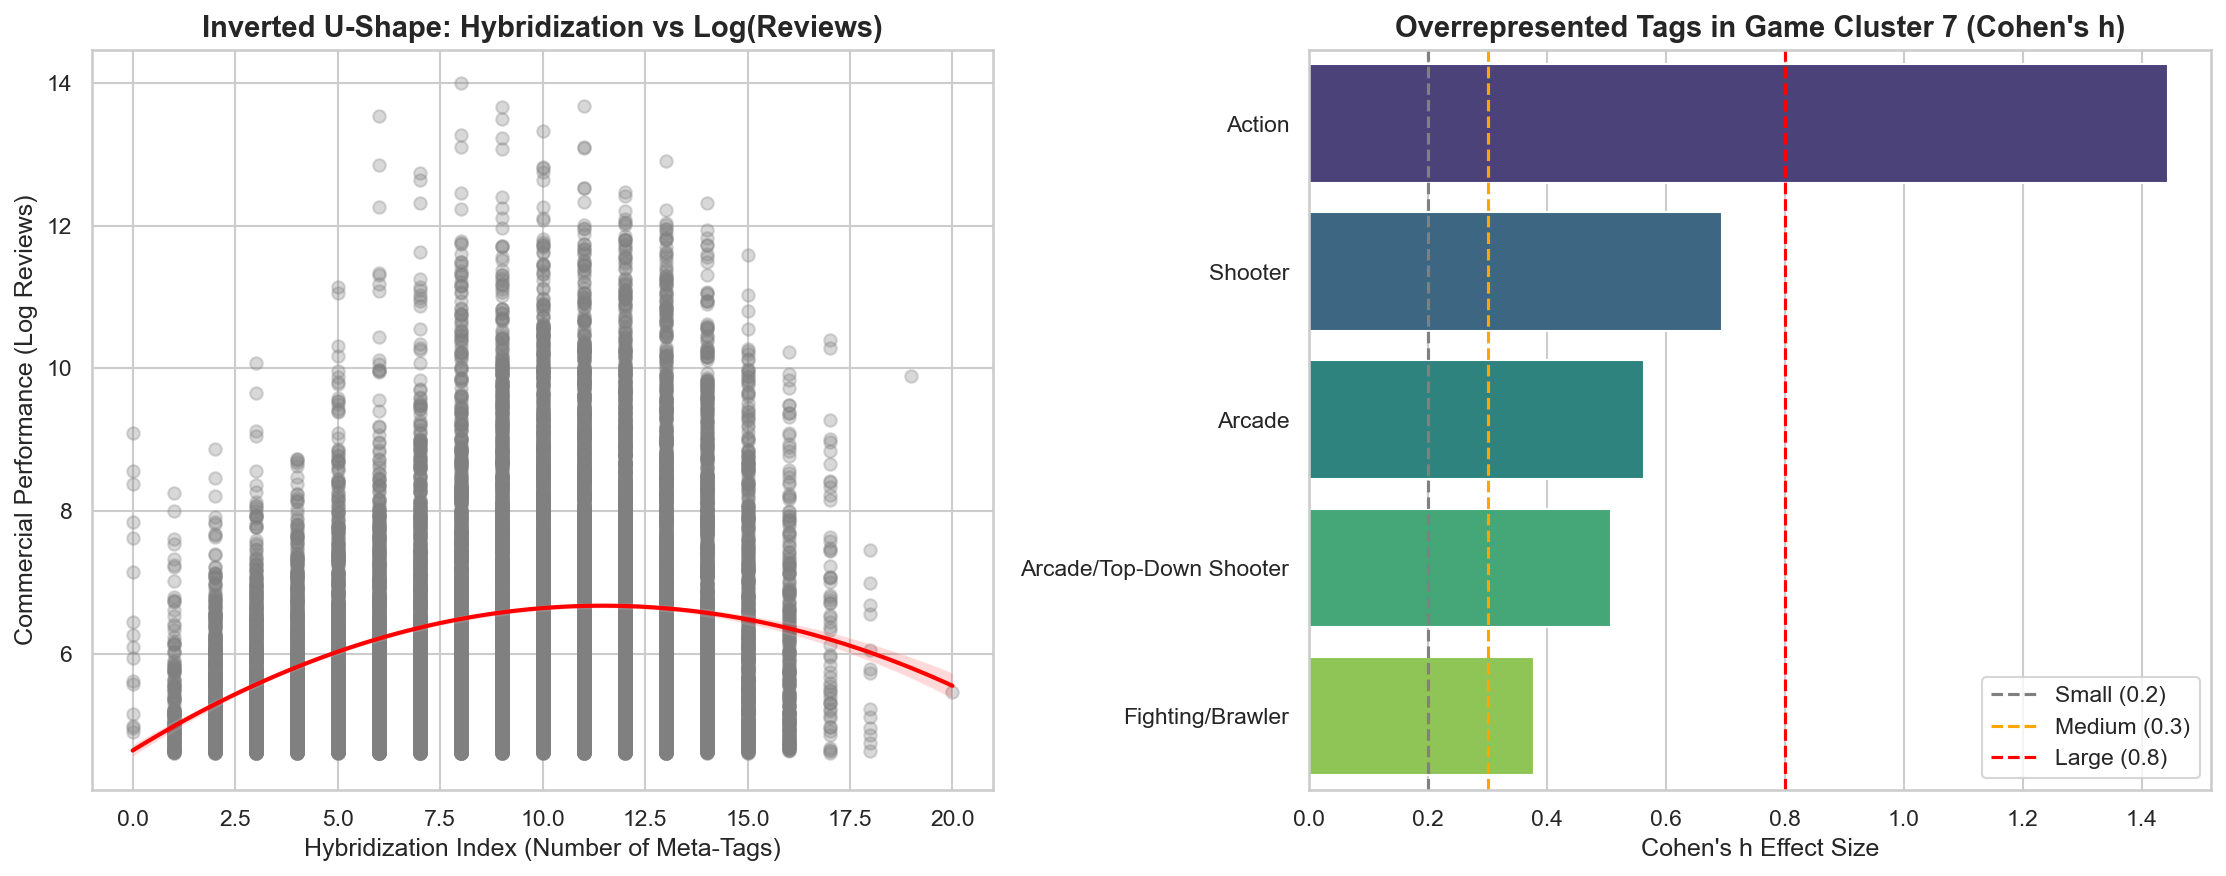


[重构完成] 已在游戏样本空间完成 TF-IDF 聚类及其全流程分析。


In [ ]:
print("\n" + "=" * 60)
print("Step 7: 可视化")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 图1：倒U型回归曲线（标签多样性 vs 商业表现）
sns.regplot(
    data=data,
    x="Hybridization_Index",
    y="Log_Reviews",
    order=2,
    scatter_kws={"alpha": 0.3, "color": "gray"},
    line_kws={"color": "red", "linewidth": 2},
    ax=axes[0],
)
axes[0].set_title(
    "Inverted U-Shape: Hybridization vs Log(Reviews)", fontsize=14, fontweight="bold"
)
axes[0].set_xlabel("Hybridization Index (Number of Meta-Tags)", fontsize=12)
axes[0].set_ylabel("Commercial Performance (Log Reviews)", fontsize=12)

# 图2：Cohen's h 超额代表性（取规模最大的游戏簇为示例）
first_cid = data["Game_Cluster"].value_counts().idxmax()
if first_cid in all_top_h:
    tags, scores = zip(*all_top_h[first_cid])
    sns.barplot(x=list(scores), y=list(tags), ax=axes[1], palette="viridis")
    axes[1].set_title(
        f"Overrepresented Tags in Game Cluster {first_cid} (Cohen's h)",
        fontsize=14,
        fontweight="bold",
    )
    axes[1].set_xlabel("Cohen's h Effect Size", fontsize=12)
    axes[1].axvline(0.2, color="gray", linestyle="--", label="Small (0.2)")
    axes[1].axvline(0.3, color="orange", linestyle="--", label="Medium (0.3)")
    axes[1].axvline(0.8, color="red", linestyle="--", label="Large (0.8)")
    axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_FIGURE, dpi=150, bbox_inches="tight")
plt.show()

print("\n[重构完成] 已在游戏样本空间完成 TF-IDF 聚类及其全流程分析。")


In [ ]:
# ============================================================
# C4 修正：结果落盘（原先全部回归结果只 print 到控制台，无法被引用/复核）
# ============================================================
from pathlib import Path as _Path

_RES_DIR = _Path("02_pipeline/results")
_RES_DIR.mkdir(parents=True, exist_ok=True)


def _row(name, mdl, b1, b2, pk):
    return {
        "table": name, "N": int(mdl.nobs), "R2": mdl.rsquared, "adj_R2": mdl.rsquared_adj,
        "beta1_Hc": b1, "se_HC3_Hc": mdl.bse["Hybrid_Centered"],
        "t_HC3_Hc": mdl.tvalues["Hybrid_Centered"],
        "beta2_Hc2": b2, "se_HC3_Hc2": mdl.bse["Hybrid_Centered_Squared"],
        "t_HC3_Hc2": mdl.tvalues["Hybrid_Centered_Squared"],
        "beta3_price": mdl.params["price"], "se_HC3_price": mdl.bse["price"],
        "t_HC3_price": mdl.tvalues["price"], "peak": pk,
    }


pd.DataFrame([
    _row("Table 5 主模型 (年份FE)", final_model, lin, quad, peak),
    _row("Table 6 稳健1 无时间控制", m0, lin0, quad0, peak0),
    _row("Table 7 稳健2 按天年龄控制", m_age, linA, quadA, peakA),
    _row("Table 8 稳健3 价格调制", m_inter, linI, quadI, peakI),
]).to_csv(_RES_DIR / "regression_summary.csv", index=False, encoding="utf-8-sig")

# 描述统计（论文 Table 1 / Table 4 的替代来源）
_idx = data["Hybridization_Index"]
pd.DataFrame([{
    "sample": "analysis (17,686)", "N": len(_idx), "mean": _idx.mean(),
    "median": _idx.median(), "sd": _idx.std(ddof=1), "min": _idx.min(), "max": _idx.max(),
}]).to_csv(_RES_DIR / "table1_index_descriptives.csv", index=False, encoding="utf-8-sig")

# 发行年份分布（论文 §4.1 的替代来源）
_vc = data["Release_Year"].value_counts().sort_index()
pd.DataFrame({
    "year": _vc.index.astype(int), "N": _vc.values,
    "share_pct": (100 * _vc.values / len(data)).round(2),
}).to_csv(_RES_DIR / "year_distribution.csv", index=False, encoding="utf-8-sig")

print(f"[written] {_RES_DIR / 'regression_summary.csv'}")
print(f"[written] {_RES_DIR / 'table1_index_descriptives.csv'}")
print(f"[written] {_RES_DIR / 'year_distribution.csv'}")
